In [28]:
import pandas as pd
import re
import matplotlib.pyplot as plt
from scipy.interpolate import CubicSpline
import numpy as np

In [29]:
file1 = 'moratab_combined_output_final NO run1.csv'
file2 = 'moratab_combined_output_final NO run2.csv'
file3 = 'moratab_combined_output_final NO run3.csv'

file4 = 'moratab_combined_output_final O2 run1.csv'
file5 = 'moratab_combined_output_final O2 run2.csv'
file6 = 'moratab_combined_output_final O2 run3.csv'

#file7 = r'C:\Users\Lenovo\Desktop\H2O2_without linker\H2O2_without_linker\New run\moratab_10H2O2_run1.csv'
#file8 = r'C:\Users\Lenovo\Desktop\H2O2_without linker\H2O2_without_linker\New run\moratab_10H2O2_run2.csv'
#file9 = r'C:\Users\Lenovo\Desktop\H2O2_without linker\H2O2_without_linker\New run\moratab_10H2O2_run3.csv'


df1 = pd.read_csv(file1)
df2 = pd.read_csv(file2)
df3 = pd.read_csv(file3)
df4 = pd.read_csv(file4)
df5 = pd.read_csv(file5)
df6 = pd.read_csv(file6)
#df7 = pd.read_csv(file7)
#df8 = pd.read_csv(file8)
#df9 = pd.read_csv(file9)


In [30]:
df1=df1[~df1['Amino 1'].str.contains("H2O2")]
df2=df2[~df2['Amino 1'].str.contains("H2O2")]
df3=df3[~df3['Amino 1'].str.contains("H2O2")]
df4=df4[~df4['Amino 1'].str.contains("H2O2")]
df5=df5[~df5['Amino 1'].str.contains("H2O2")]
df6=df6[~df6['Amino 1'].str.contains("H2O2")]
#df7=df7[~df7['Amino 1'].str.contains("H2O2")]
#df8=df8[~df8['Amino 1'].str.contains("H2O2")]
#df9=df9[~df9['Amino 1'].str.contains("H2O2")]


In [31]:
# تابع برای حذف حروف از رشته و نگه داشتن اعداد
def remove_letters(s):
    return ''.join(re.findall(r'\d+', s))

# اعمال تابع بر روی ستون "Amino 1"
df1['Amino 1'] = df1['Amino 1'].apply(remove_letters)
df2['Amino 1'] = df2['Amino 1'].apply(remove_letters)
df3['Amino 1'] = df3['Amino 1'].apply(remove_letters)
df4['Amino 1'] = df4['Amino 1'].apply(remove_letters)
df5['Amino 1'] = df5['Amino 1'].apply(remove_letters)
df6['Amino 1'] = df6['Amino 1'].apply(remove_letters)
#df7['Amino 1'] = df7['Amino 1'].apply(remove_letters)
#df8['Amino 1'] = df8['Amino 1'].apply(remove_letters)
#df9['Amino 1'] = df9['Amino 1'].apply(remove_letters)

# ذخیره داده‌های ویرایش شده به فایل CSV جدید
#df1.to_csv('number_.csv', index=False)
#print(df1)

In [32]:
merged_df_1 = pd.concat([df1, df2, df3])
merged_df_2 = pd.concat([df4, df5, df6])
#merged_df_3 = pd.concat([df7, df8, df9])

In [33]:
print(merged_df_1 )

   Amino 1  Amino 3  first frame  final frame  total frame count  \
0      686  712H2O2          223          232                 10   
1      686  712H2O2          234          298                 65   
2      699  712H2O2          287          292                  6   
3      675  712H2O2          451          457                  7   
4      673  712H2O2          461          474                 14   
..     ...      ...          ...          ...                ...   
69     671  712H2O2        48340        48356                 17   
70     671  712H2O2        48358        48360                  3   
71     671  712H2O2        48449        48459                 11   
72     671  712H2O2        48462        48468                  7   
73     670  712H2O2        48469        48472                  4   

    total hbond count  
0                  10  
1                  74  
2                   8  
3                  17  
4                  14  
..                ...  
69             

In [34]:
def sum_total_frame_count(df):

    # گروه‌بندی داده‌ها بر اساس ستون 'Amino 1' و جمع کردن مقادیر 'total frame count'
    df_grouped = df.groupby('Amino 1', as_index=False)['total frame count'].sum()

    return df_grouped


# فراخوانی تابع و مشاهده نتایج
result_df1 = sum_total_frame_count(merged_df_1 )
result_df2 = sum_total_frame_count(merged_df_2 )
#result_df3 = sum_total_frame_count(merged_df_3 )

#print(result_df)

In [35]:
#print(result_df1)
print(result_df2)


   Amino 1  total frame count
0      640                 26
1      643               1542
2      644                 60
3      645                 10
4      646                719
5      647                 19
6      649                828
7      650                632
8      652                313
9      664                  9
10     666                150
11     667                 69
12     669                 53
13     670                 10
14     671                146
15     672                 32
16     673                 29
17     675                  4
18     676                 38
19     690                  6
20     691                 54
21     692                 42
22     694                206
23     695                 30
24     697                316
25     702                  6
26     707                364
27     708                 55
28     710                 87


In [36]:
def fill_missing_numbers(data):
    # اطمینان از اینکه نوع داده ستون 'Amino 1' در هر دو DataFrame یکسان باشد
    data['Amino 1'] = data['Amino 1'].astype(int)
    
    # ایجاد یک DataFrame با تمامی اعداد در محدوده 628 تا 711
    all_numbers = pd.DataFrame({'Amino 1': range(628, 712)})

    # ادغام DataFrame اصلی با DataFrame همه اعداد
    data_filled = all_numbers.merge(data, on='Amino 1', how='left').fillna(0)

    return data_filled

# تغییر نوع داده ستون 'Amino 1' به int
result_df1['Amino 1'] =result_df1['Amino 1'].astype(int)
result_df2['Amino 1'] =result_df2['Amino 1'].astype(int)
#result_df3['Amino 1'] =result_df3['Amino 1'].astype(int)

# فراخوانی تابع
final_df1 = fill_missing_numbers(result_df1)
final_df2 = fill_missing_numbers(result_df2)
#final_df3 = fill_missing_numbers(result_df3)
#final_df=pd.DataFrame(final_df1)
# ذخیره داده‌های ویرایش شده به فایل CSV جدید
#output_file_path = 'path_to_your_output_file.csv'
final_df1.to_csv('hbond_extra_HP-NO.csv', index=False)
final_df2.to_csv('hbond_extra_HP-O2.csv', index=False)
#final_df3.to_csv('10H2O2.csv', index=False)
print(final_df1)

    Amino 1  total frame count
0       628               50.0
1       629              109.0
2       630               80.0
3       631                0.0
4       632                0.0
..      ...                ...
79      707              165.0
80      708                0.0
81      709                0.0
82      710               11.0
83      711                0.0

[84 rows x 2 columns]


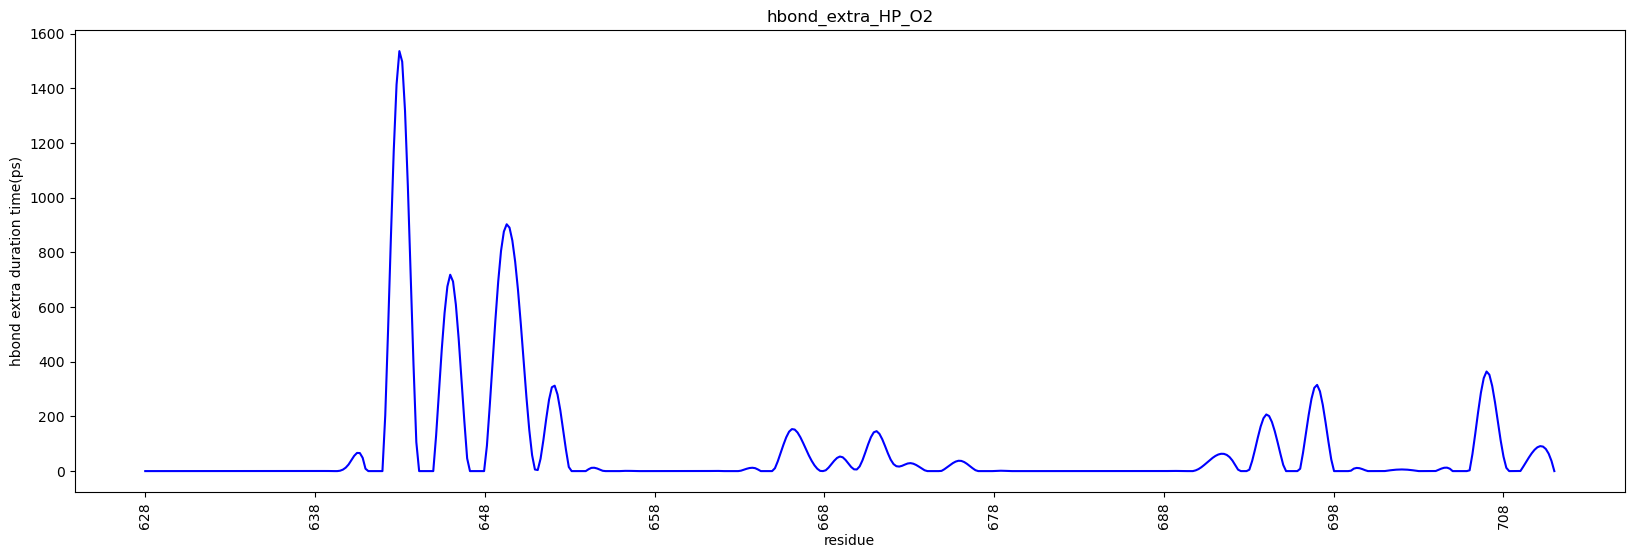

In [53]:
def plot_sorted_data(df):

    # مرتب‌سازی داده‌ها بر اساس ستون 'Amino 1'
    df_sorted = df.sort_values(by='Amino 1')
    cs = CubicSpline(df_sorted['Amino 1'], df_sorted['total frame count'])
    # رسم نمودار خطی
    plt.figure(figsize=(20, 6))
    #plt.plot(df_sorted['Amino 1'], df_sorted['total frame count'], marker='o', linestyle='-', color='b')

    x_new = np.linspace(df_sorted['Amino 1'].min(), df_sorted['Amino 1'].max(), 500)
    y_new = cs(x_new)
    y_new = np.where(y_new < 0 ,0 , y_new)
# رسم نمودار اصلی و نمودار هموار شده
    
    plt.plot(x_new, y_new, label='Smoothed Line', color='blue')
    # تنظیمات نمودار
    plt.xlabel('residue')
    plt.ylabel('hbond extra duration time(ps)')
    plt.title('hbond_extra_HP_O2')
    plt.xticks(np.arange(min(x_new),max(x_new)+1,10),rotation=90)
    plt.grid(False)
    plt.savefig('hbond_extra_HP_O2 duration time(ps).png',dpi=500)
    # نمایش نمودار
    plt.show()

plot_sorted_data(final_df2)

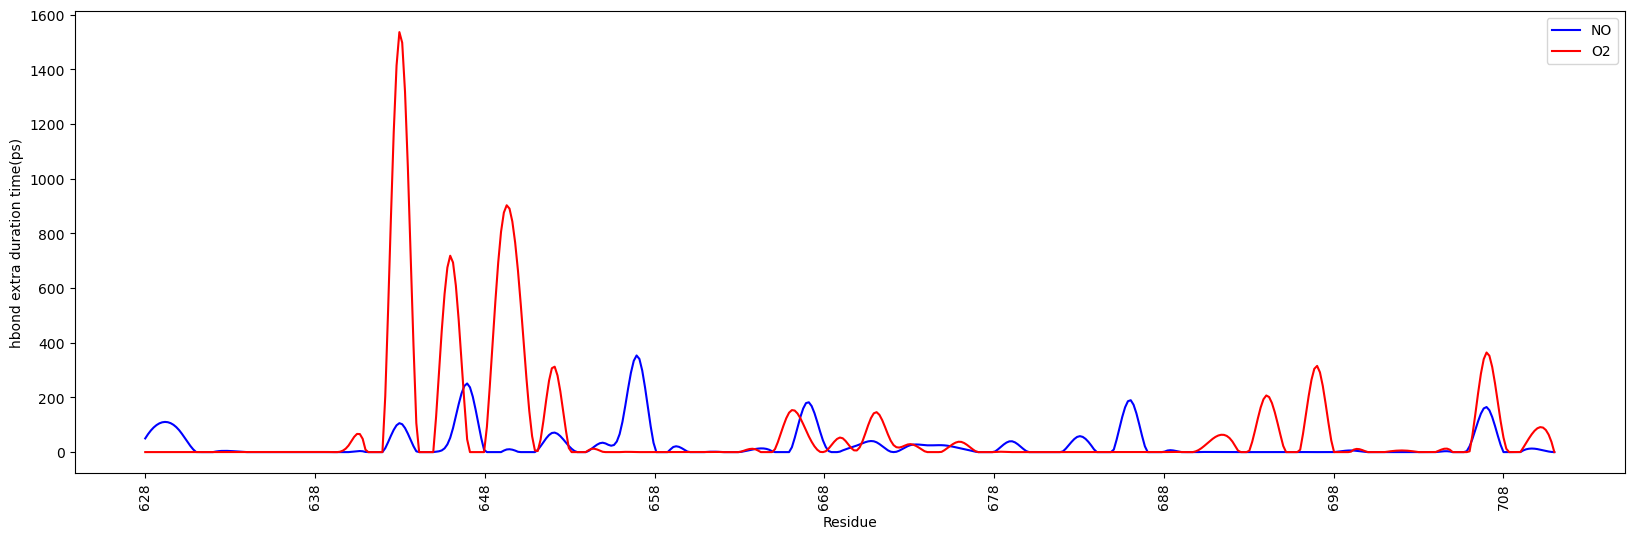

In [38]:
def plot_sorted_data(df1,df2):#,df3

    # مرتب‌سازی داده‌ها بر اساس ستون 'Amino 1'
    df1_sorted = df1.sort_values(by='Amino 1')
    df2_sorted = df2.sort_values(by='Amino 1')
    #df3_sorted = df3.sort_values(by='Amino 1')
    cs1 = CubicSpline(df1_sorted['Amino 1'], df1_sorted['total frame count'])
    cs2 = CubicSpline(df2_sorted['Amino 1'], df2_sorted['total frame count'])
    #cs3 = CubicSpline(df3_sorted['Amino 1'], df3_sorted['total frame count'])

    # رسم نمودار خطی
    plt.figure(figsize=(20, 6))
    #plt.plot(df_sorted['Amino 1'], df_sorted['total frame count'], marker='o', linestyle='-', color='b')

    x1_new = np.linspace(df1_sorted['Amino 1'].min(), df1_sorted['Amino 1'].max(), 500)
    y1_new = cs1(x1_new)
    y1_new = np.where(y1_new < 0 ,0 , y1_new)

    x2_new = np.linspace(df2_sorted['Amino 1'].min(), df2_sorted['Amino 1'].max(), 500)
    y2_new = cs2(x2_new)
    y2_new = np.where(y2_new < 0 ,0 , y2_new)

    #x3_new = np.linspace(df3_sorted['Amino 1'].min(), df3_sorted['Amino 1'].max(), 500)
    #y3_new = cs3(x3_new)
    #y3_new = np.where(y3_new < 0 ,0 , y3_new)
# رسم نمودار اصلی و نمودار هموار شده
    
    plt.plot(x1_new, y1_new, label='NO', color='blue')
    plt.plot(x2_new, y2_new, label='O2', color='red')
    #plt.plot(x3_new, y3_new, label='10 H2O2', color='green')
    # تنظیمات نمودار
    plt.xlabel('Residue')
    plt.ylabel('hbond extra duration time(ps)')
    #plt.title('1 H2O2')
    plt.xticks(np.arange(min(x1_new),max(x1_new)+1,10),rotation=90)
    plt.grid(False)
    plt.legend()
    plt.savefig('hbond extra NO and O2.png',dpi=500)
    # نمایش نمودار
    plt.show()

plot_sorted_data(final_df1,final_df2)#,final_df3